# 🫁 Chest X-Ray Pneumonia Classifier — MLOps Notebook

**Assignment:** MLOps Summative — End-to-End ML Pipeline  
**Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)  
**Model:** MobileNetV2 Transfer Learning (Binary Classification: NORMAL vs PNEUMONIA)  

---

## Pipeline Overview

| Step | Description |
|------|-------------|
| 1 | Install dependencies |
| 2 | Load & explore the dataset |
| 3 | Preprocess images (resize, normalize, augment) |
| 4 | Exploratory Data Analysis (EDA) |
| 5 | Build MobileNetV2 model |
| 6 | Train — Phase 1 (frozen base) |
| 7 | Fine-tune — Phase 2 (unfreeze top 20 layers) |
| 8 | Evaluate with 6 metrics |
| 9 | Save model & download |
| 10 | Prediction demo |


---
## Step 1 — Install Dependencies

We install all required libraries. TensorFlow comes pre-installed on Google Colab with GPU support, but we explicitly pin versions to ensure reproducibility.

In [4]:
# Install / upgrade required packages
# (Most are already on Colab; this ensures the correct versions are present)
!pip install -q scikit-learn matplotlib seaborn Pillow numpy pandas

In [5]:
import os
import io
import json
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.metrics import Precision, Recall, AUC
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc as sklearn_auc,
    f1_score,
    precision_score,
    recall_score,
)

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: False
GPU devices: []


---
## Step 2 — Load the Dataset

We use the [Kaggle Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) dataset.
It contains **5,863 JPEG chest X-ray images** organised into two classes:

- **NORMAL** — healthy lung X-rays
- **PNEUMONIA** — X-rays showing either bacterial or viral pneumonia

**Option A (Recommended in Colab):** Use `tensorflow_datasets` — no Kaggle credentials needed.  
**Option B:** Upload dataset manually from Kaggle and unzip.

In [6]:
# ── Load dataset via Kaggle API ───────────────────────────────────────────────
# Step 1: Upload your kaggle.json API key when prompted

from google.colab import files
import os, zipfile

# Upload kaggle.json (get it from kaggle.com → Account → API → Create New Token)
uploaded = files.upload()  # select your kaggle.json file

# Set up Kaggle credentials
os.makedirs('/root/.config/kaggle', exist_ok=True)
with open('/root/.config/kaggle/kaggle.json', 'wb') as f:
    f.write(uploaded['kaggle.json'])
os.chmod('/root/.config/kaggle/kaggle.json', 0o600)

# Download the dataset
!pip install -q kaggle
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip -q chest-xray-pneumonia.zip

# Set paths
TRAIN_DIR = '/content/chest_xray/train'
TEST_DIR  = '/content/chest_xray/test'
VAL_DIR   = '/content/chest_xray/val'
CLASS_NAMES = ['NORMAL', 'PNEUMONIA']
IMG_SIZE = 224
BATCH_SIZE = 32

print("Dataset downloaded!")
import os
for split in ['train', 'test', 'val']:
    for cls in ['NORMAL', 'PNEUMONIA']:
        path = f'/content/chest_xray/{split}/{cls}'
        if os.path.exists(path):
            print(f"  {split}/{cls}: {len(os.listdir(path))} images")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:24<00:00, 102MB/s] 

Dataset downloaded!
  train/NORMAL: 1341 images
  train/PNEUMONIA: 3875 images
  test/NORMAL: 234 images
  test/PNEUMONIA: 390 images
  val/NORMAL: 8 images
  val/PNEUMONIA: 8 images


---
## Step 3 — Preprocessing

Preprocessing converts raw images into normalized tensors suitable for MobileNetV2:

1. **Resize** every image to 224×224 pixels (MobileNetV2's expected input size)
2. **Normalize** pixel values from `[0, 255]` → `[0.0, 1.0]`
3. **One-hot encode** labels for categorical crossentropy loss
4. **Data augmentation** on the training set only:
   - Random horizontal flip
   - Random rotation up to ±15°
   - Random zoom up to ±10%
   - Brightness jitter in `[0.8, 1.2]`

In [7]:
# ── Preprocessing with ImageDataGenerator ────────────────────────────────────
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 32

# Training generator WITH augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    horizontal_flip=True,
    rotation_range=15,
    zoom_range=0.1,
    brightness_range=[0.8, 1.2],
    validation_split=0.2  # use 20% of train as validation
)

# Test generator — NO augmentation
test_datagen = ImageDataGenerator(rescale=1.0/255)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
)

val_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
)

test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

print(f"Train samples:      {train_gen.samples}")
print(f"Validation samples: {val_gen.samples}")
print(f"Test samples:       {test_gen.samples}")
print(f"Classes: {train_gen.class_indices}")

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Train samples:      4173
Validation samples: 1043
Test samples:       624
Classes: {'NORMAL': 0, 'PNEUMONIA': 1}


---
## Step 4 — Exploratory Data Analysis (EDA)

Before training, we explore the dataset to understand its structure:
1. Class distribution (are classes balanced?)
2. Sample images from each class
3. Pixel intensity distributions

Understanding the data first helps us choose the right model design and interpret results.

NORMAL:    1341 (25.7%)
PNEUMONIA: 3875 (74.3%)
Imbalance ratio: 2.9:1


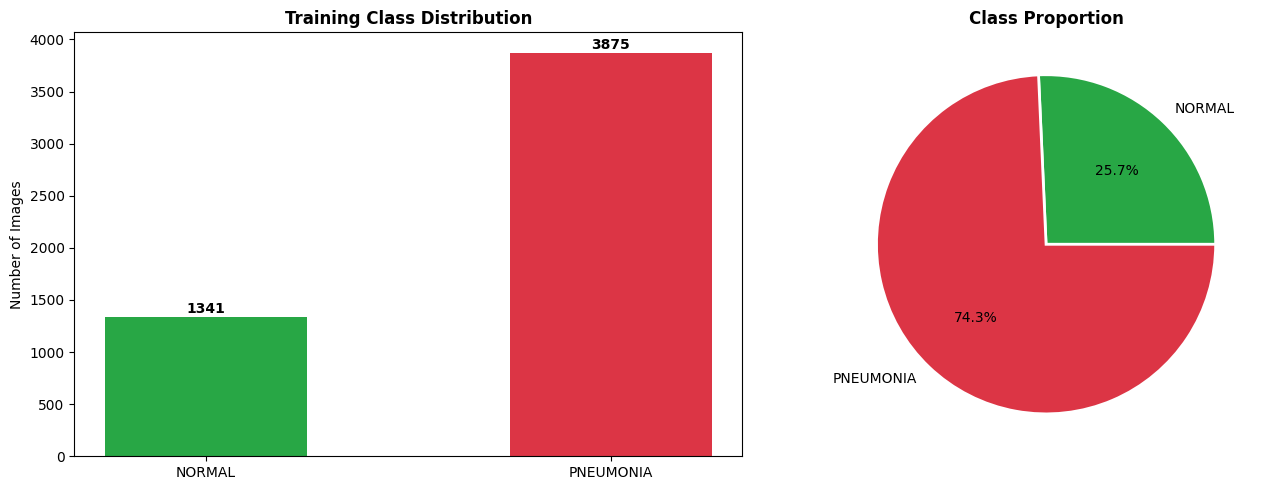


📊 Interpretation — Feature 1: Class Distribution
PNEUMONIA has 2.9x more images than NORMAL.
This imbalance can bias the model — we use augmentation and monitor F1/Recall.


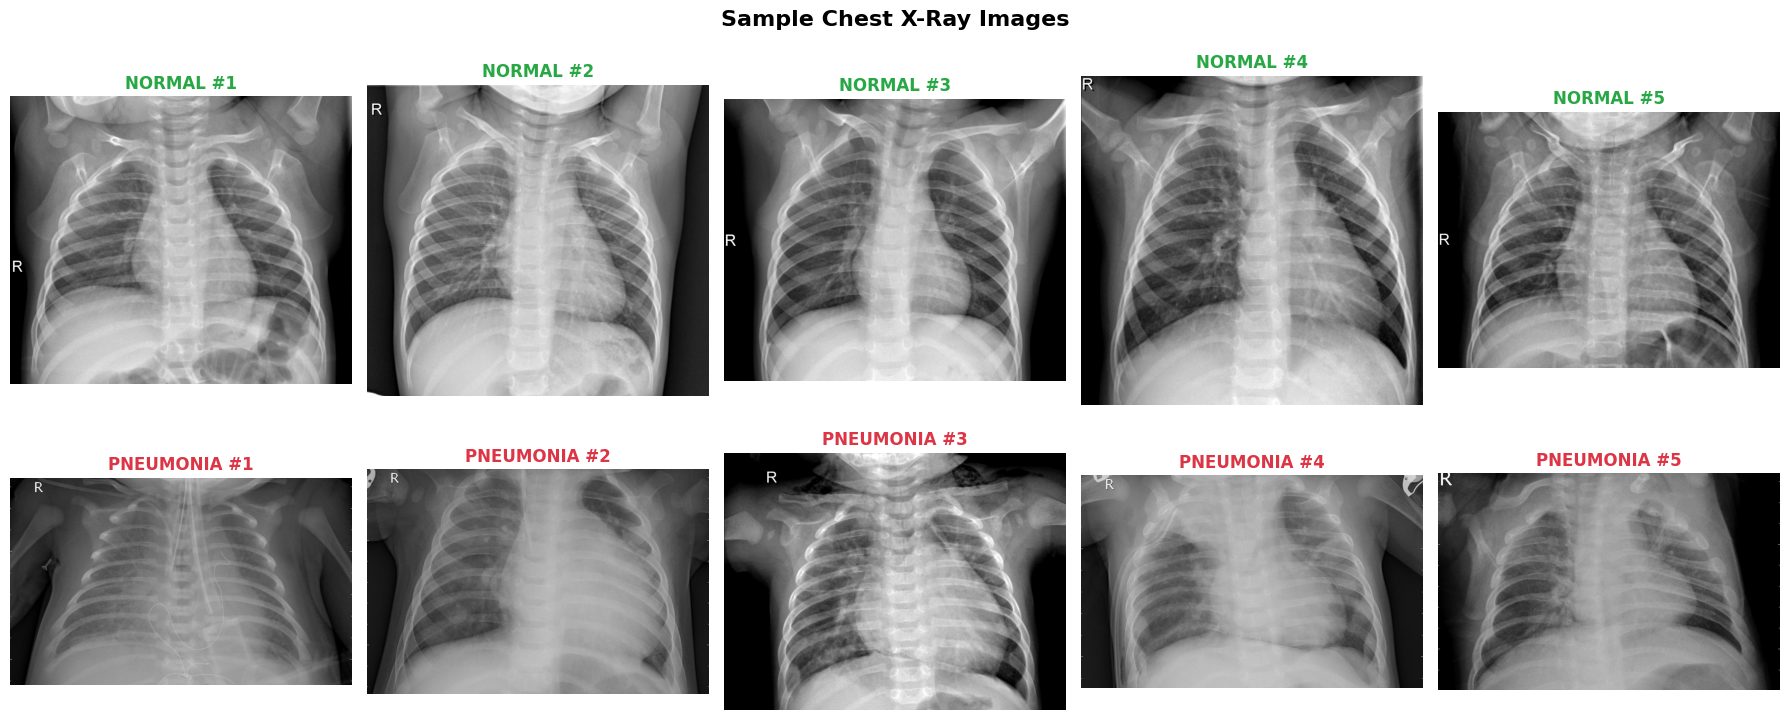


📊 Interpretation — Feature 2: Visual Differences
NORMAL: clear, dark lung fields. PNEUMONIA: cloudy/hazy patches (consolidation).


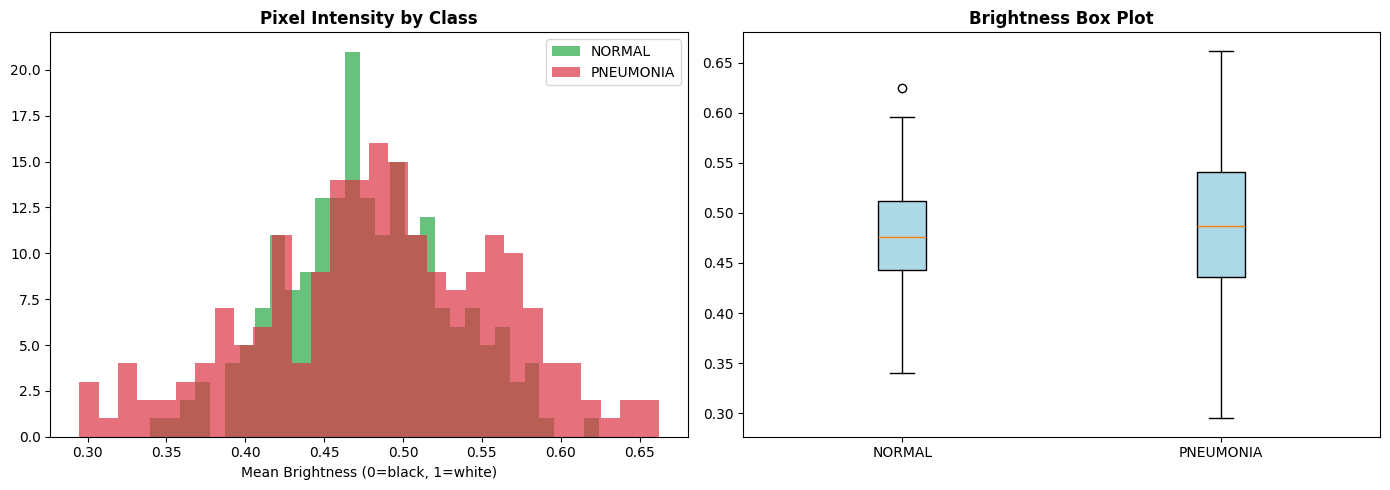


📊 Interpretation — Feature 3: Pixel Intensity
NORMAL mean brightness:    0.4772
PNEUMONIA mean brightness: 0.4850
PNEUMONIA lungs appear BRIGHTER because fluid/consolidation shows as white on X-ray.


In [8]:
# ── EDA: Feature 1 — Class Distribution ──────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
import os

normal_count    = len(os.listdir(os.path.join(TRAIN_DIR, 'NORMAL')))
pneumonia_count = len(os.listdir(os.path.join(TRAIN_DIR, 'PNEUMONIA')))
total = normal_count + pneumonia_count

print(f"NORMAL:    {normal_count} ({normal_count/total:.1%})")
print(f"PNEUMONIA: {pneumonia_count} ({pneumonia_count/total:.1%})")
print(f"Imbalance ratio: {pneumonia_count/normal_count:.1f}:1")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(['NORMAL', 'PNEUMONIA'], [normal_count, pneumonia_count],
            color=['#28a745', '#dc3545'], width=0.5)
axes[0].set_title('Training Class Distribution', fontweight='bold')
axes[0].set_ylabel('Number of Images')
for i, v in enumerate([normal_count, pneumonia_count]):
    axes[0].text(i, v + 30, str(v), ha='center', fontweight='bold')

axes[1].pie([normal_count, pneumonia_count], labels=['NORMAL', 'PNEUMONIA'],
            colors=['#28a745', '#dc3545'], autopct='%1.1f%%',
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Proportion', fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Interpretation — Feature 1: Class Distribution")
print(f"PNEUMONIA has {pneumonia_count/normal_count:.1f}x more images than NORMAL.")
print("This imbalance can bias the model — we use augmentation and monitor F1/Recall.")

# ── Feature 2 — Sample Images ─────────────────────────────────────────────────
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
fig.suptitle('Sample Chest X-Ray Images', fontsize=16, fontweight='bold')

for i, cls in enumerate(['NORMAL', 'PNEUMONIA']):
    folder = os.path.join(TRAIN_DIR, cls)
    files  = [f for f in os.listdir(folder) if f.endswith(('.jpg','.jpeg','.png'))][:5]
    for j, fname in enumerate(files):
        img = Image.open(os.path.join(folder, fname)).convert('RGB')
        axes[i][j].imshow(img, cmap='bone')
        color = '#28a745' if cls == 'NORMAL' else '#dc3545'
        axes[i][j].set_title(f'{cls} #{j+1}', color=color, fontweight='bold')
        axes[i][j].axis('off')

plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Interpretation — Feature 2: Visual Differences")
print("NORMAL: clear, dark lung fields. PNEUMONIA: cloudy/hazy patches (consolidation).")

# ── Feature 3 — Pixel Intensity ───────────────────────────────────────────────
normal_bright, pneumo_bright = [], []

for cls, lst in [('NORMAL', normal_bright), ('PNEUMONIA', pneumo_bright)]:
    folder = os.path.join(TRAIN_DIR, cls)
    files  = [f for f in os.listdir(folder) if f.endswith(('.jpg','.jpeg','.png'))][:200]
    for fname in files:
        img = np.array(Image.open(os.path.join(folder, fname)).convert('RGB'), dtype=np.float32) / 255.0
        lst.append(float(img.mean()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(normal_bright,  bins=30, alpha=0.7, color='#28a745', label='NORMAL')
axes[0].hist(pneumo_bright,  bins=30, alpha=0.7, color='#dc3545', label='PNEUMONIA')
axes[0].set_title('Pixel Intensity by Class', fontweight='bold')
axes[0].set_xlabel('Mean Brightness (0=black, 1=white)')
axes[0].legend()

axes[1].boxplot([normal_bright, pneumo_bright], labels=['NORMAL', 'PNEUMONIA'],
                patch_artist=True, boxprops=dict(facecolor='lightblue'))
axes[1].set_title('Brightness Box Plot', fontweight='bold')

plt.tight_layout()
plt.savefig('pixel_intensity.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📊 Interpretation — Feature 3: Pixel Intensity")
print(f"NORMAL mean brightness:    {sum(normal_bright)/len(normal_bright):.4f}")
print(f"PNEUMONIA mean brightness: {sum(pneumo_bright)/len(pneumo_bright):.4f}")
print("PNEUMONIA lungs appear BRIGHTER because fluid/consolidation shows as white on X-ray.")

---
## Step 5 — Build the MobileNetV2 Model

**Architecture:** Transfer Learning with MobileNetV2

MobileNetV2 was pre-trained on ImageNet (1.4M images, 1000 classes). We replace its classification head with our own binary head and use the pre-trained feature extractor as a frozen base.

**Why MobileNetV2?**
- Lightweight (~14MB) — fast inference, suitable for Render free tier
- Pre-trained feature extractors generalize well to medical images
- Inverted residuals + linear bottlenecks prevent gradient vanishing

**Custom head:**
```
MobileNetV2 (frozen) → GlobalAveragePooling2D → Dense(128, relu)
→ Dropout(0.3) → Dense(64, relu) → Dropout(0.2) → Dense(2, softmax)
```

**Optimization techniques used:**
- Dropout layers (regularization against overfitting)
- Adam optimizer with learning rate scheduling
- Early stopping (stops when val_loss stops improving)
- ReduceLROnPlateau (halves LR when stuck)
- ModelCheckpoint (saves best model automatically)

In [9]:
# ── Build MobileNetV2 transfer learning model ─────────────────────────────────

INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
NUM_CLASSES = 2
LEARNING_RATE_PHASE1 = 1e-4

def build_model(input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES, lr=LEARNING_RATE_PHASE1):
    """
    Build and compile a MobileNetV2 transfer learning model.

    Phase 1: Base is FROZEN — only the custom head is trained.
    This is faster and prevents destroying pre-trained features early on.
    """
    # ---- Base model: MobileNetV2 pre-trained on ImageNet ----
    base_model = MobileNetV2(
        weights='imagenet',         # start from ImageNet weights
        include_top=False,          # remove the classification head
        input_shape=input_shape,
    )
    base_model.trainable = False    # FREEZE base layers in Phase 1

    # ---- Custom classification head ----
    inputs  = keras.Input(shape=input_shape, name='input_image')
    x       = base_model(inputs, training=False)              # feature extraction
    x       = layers.GlobalAveragePooling2D(name='gap')(x)    # reduce spatial dims
    x       = layers.Dense(128, activation='relu', name='dense_128')(x)
    x       = layers.Dropout(0.3, name='dropout_0.3')(x)      # regularization
    x       = layers.Dense(64,  activation='relu', name='dense_64')(x)
    x       = layers.Dropout(0.2, name='dropout_0.2')(x)      # regularization
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = keras.Model(inputs, outputs, name='chest_xray_mobilenetv2')

    # ---- Compile with 4 metrics ----
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=[
            'accuracy',
            Precision(name='precision'),
            Recall(name='recall'),
            AUC(name='auc'),
        ],
    )
    return model


model = build_model()
model.summary()
print(f"\nTotal parameters: {model.count_params():,}")
print(f"Trainable parameters: {sum(tf.size(w).numpy() for w in model.trainable_weights):,}")
print(f"Non-trainable parameters: {sum(tf.size(w).numpy() for w in model.non_trainable_weights):,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "chest_xray_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0.3 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0.2 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,430,338 (9.27 MB)

 Trainable params: 172,354 (673.26 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Total parameters: 2,430,338
Trainable parameters: 172,354
Non-trainable parameters: 2,257,984


---
## Step 6 — Train Phase 1 (Frozen Base)

In Phase 1, the MobileNetV2 base is **frozen** — only the custom head layers are trained.

**Why freeze the base first?**  
The base contains 2.2M parameters pre-trained on ImageNet. If we immediately allow these to update with our small dataset, the weights will be corrupted by random head gradients — a problem called "catastrophic forgetting". By freezing the base first, we let the head find a sensible starting point before the base adapts.

**Callbacks used:**
- `EarlyStopping`: stops training if val_loss doesn't improve for 3 epochs
- `ReduceLROnPlateau`: halves the learning rate when val_loss plateaus (2 epochs patience)
- `ModelCheckpoint`: saves the best model weights automatically

In [10]:
# ── Training Phase 1: Custom head only (frozen base) ─────────────────────────
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

EPOCHS_PHASE1 = 3  # 3 epochs for speed on CPU

callbacks_phase1 = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1),
    ModelCheckpoint(filepath='best_model_phase1.h5', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
]

print("=" * 60)
print("PHASE 1 — Training custom head (base frozen)")
print(f"Epochs: {EPOCHS_PHASE1}")
print("=" * 60)

history_phase1 = model.fit(
    train_gen,
    epochs=EPOCHS_PHASE1,
    validation_data=val_gen,
    callbacks=callbacks_phase1,
    verbose=1,
)

print(f"\nPhase 1 done. Best val_accuracy: {max(history_phase1.history['val_accuracy']):.4f}")

PHASE 1 — Training custom head (base frozen)
Epochs: 3
Epoch 1/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7861 - auc: 0.8620 - loss: 0.4609 - precision: 0.7861 - recall: 0.7861
Epoch 1: val_accuracy improved from None to 0.92522, saving model to best_model_phase1.h5



Epoch 1: finished saving model to best_model_phase1.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 435s 3s/step - accuracy: 0.8344 - auc: 0.9190 - loss: 0.3595 - precision: 0.8344 - recall: 0.8344 - val_accuracy: 0.9252 - val_auc: 0.9774 - val_loss: 0.2084 - val_precision: 0.9252 - val_recall: 0.9252 - learning_rate: 1.0000e-04
Epoch 2/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9038 - auc: 0.9687 - loss: 0.2282 - precision: 0.9038 - recall: 0.9038
Epoch 2: val_accuracy improved from 0.92522 to 0.93289, saving model to best_model_phase1.h5



Epoch 2: finished saving model to best_model_phase1.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 405s 3s/step - accuracy: 0.9171 - auc: 0.9750 - loss: 0.2051 - precision: 0.9171 - recall: 0.9171 - val_accuracy: 0.9329 - val_auc: 0.9826 - val_loss: 0.1699 - val_precision: 0.9329 - val_recall: 0.9329 - learning_rate: 1.0000e-04
Epoch 3/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9240 - auc: 0.9796 - loss: 0.1833 - precision: 0.9240 - recall: 0.9240
Epoch 3: val_accuracy improved from 0.93289 to 0.94823, saving model to best_model_phase1.h5



Epoch 3: finished saving model to best_model_phase1.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 408s 3s/step - accuracy: 0.9312 - auc: 0.9836 - loss: 0.1656 - precision: 0.9312 - recall: 0.9312 - val_accuracy: 0.9482 - val_auc: 0.9886 - val_loss: 0.1405 - val_precision: 0.9482 - val_recall: 0.9482 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 3.

Phase 1 done. Best val_accuracy: 0.9482


---
## Step 7 — Fine-Tune Phase 2 (Unfreeze Top 20 Layers)

Now we unfreeze the **top 20 layers** of the MobileNetV2 base so they can adapt to the chest X-ray domain. The lower layers (which detect edges and textures) remain frozen — these generic features transfer well. Only the high-level feature detectors need domain adaptation.

**Key change:** We use a **10x lower learning rate** (1e-5 instead of 1e-4) to prevent destroying the carefully learned base weights with large gradient updates.

In [11]:
# ── Training Phase 2: Fine-tune top 20 base layers ───────────────────────────
EPOCHS_PHASE2 = 3  # 3 epochs for speed on CPU

base_model = None
for layer in model.layers:
    if isinstance(layer, keras.Model):
        base_model = layer
        break

base_model.trainable = True
freeze_until = max(0, len(base_model.layers) - 20)
for layer in base_model.layers[:freeze_until]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy', Precision(name='precision'), Recall(name='recall'), AUC(name='auc')],
)

callbacks_phase2 = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-8, verbose=1),
    ModelCheckpoint(filepath='chest_xray_model.h5', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
]

print("=" * 60)
print("PHASE 2 — Fine-tuning top 20 base layers")
print("=" * 60)

history_phase2 = model.fit(
    train_gen,
    epochs=EPOCHS_PHASE2,
    validation_data=val_gen,
    callbacks=callbacks_phase2,
    verbose=1,
)

print(f"\nPhase 2 done. Best val_accuracy: {max(history_phase2.history['val_accuracy']):.4f}")

PHASE 2 — Fine-tuning top 20 base layers
Epoch 1/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8891 - auc: 0.9551 - loss: 0.2719 - precision: 0.8891 - recall: 0.8891
Epoch 1: val_accuracy improved from None to 0.92713, saving model to chest_xray_model.h5



Epoch 1: finished saving model to chest_xray_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 495s 4s/step - accuracy: 0.9089 - auc: 0.9678 - loss: 0.2329 - precision: 0.9089 - recall: 0.9089 - val_accuracy: 0.9271 - val_auc: 0.9838 - val_loss: 0.1658 - val_precision: 0.9271 - val_recall: 0.9271 - learning_rate: 1.0000e-05
Epoch 2/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9283 - auc: 0.9825 - loss: 0.1733 - precision: 0.9283 - recall: 0.9283
Epoch 2: val_accuracy did not improve from 0.92713
131/131 ━━━━━━━━━━━━━━━━━━━━ 462s 4s/step - accuracy: 0.9324 - auc: 0.9830 - loss: 0.1693 - precision: 0.9324 - recall: 0.9324 - val_accuracy: 0.9147 - val_auc: 0.9767 - val_loss: 0.2150 - val_precision: 0.9147 - val_recall: 0.9147 - learning_rate: 1.0000e-05
Epoch 3/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9404 - auc: 0.9851 - loss: 0.1561 - precision: 0.9404 - recall: 0.9404
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.

Epoch 3: val_accuracy did n

---
## Step 8 — Model Evaluation

We evaluate the model using **6 metrics** to get a complete picture of performance:

| Metric | What it measures |
|--------|------------------|
| **Accuracy** | % of all predictions that are correct |
| **Loss** | Cross-entropy loss on test set |
| **Precision** | Of all predicted PNEUMONIA, how many are truly PNEUMONIA? |
| **Recall** | Of all true PNEUMONIA cases, how many did we catch? |
| **F1 Score** | Harmonic mean of Precision and Recall |
| **ROC-AUC** | Area under the ROC curve — model's discrimination ability |

In a medical context, **Recall (sensitivity)** is most important — missing a pneumonia case is more dangerous than a false alarm.

In [12]:
# ── Evaluate on test set ──────────────────────────────────────────────────────
test_gen.reset()
print("Evaluating on test set...")
test_results = model.evaluate(test_gen, verbose=1)
metric_names  = model.metrics_names

print("\n" + "=" * 50)
print("TEST RESULTS")
print("=" * 50)
for name, val in zip(metric_names, test_results):
    print(f"  {name:12s}: {val:.4f}")

Evaluating on test set...
20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.8045 - auc: 0.8992 - loss: 0.6060 - precision: 0.8045 - recall: 0.8045

TEST RESULTS
  loss        : 0.6060
  compile_metrics: 0.8045


In [13]:
# ── Collect predictions ───────────────────────────────────────────────────────
import numpy as np

test_gen.reset()
y_true  = test_gen.classes
y_probs = model.predict(test_gen, verbose=1)
y_pred  = np.argmax(y_probs, axis=1)
y_probs_pneumonia = y_probs[:, 1]

print(f"Test samples: {len(y_true)}")
print(f"NORMAL: {(y_true==0).sum()}, PNEUMONIA: {(y_true==1).sum()}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step
Test samples: 624
NORMAL: 234, PNEUMONIA: 390


In [14]:
# ── Step 8c: Compute all 6 metrics ───────────────────────────────────────────

from sklearn.metrics import accuracy_score

accuracy   = accuracy_score(y_true, y_pred)
precision  = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
recall     = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
f1         = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

fpr, tpr, _ = roc_curve(y_true, y_probs_pneumonia)
roc_auc     = sklearn_auc(fpr, tpr)

# Loss is from model.evaluate above
loss_val = test_results[0]

print("=" * 55)
print("FULL EVALUATION METRICS — Chest X-Ray Classifier")
print("=" * 55)
print(f"  Accuracy  : {accuracy:.4f}  ({accuracy:.2%})")
print(f"  Loss      : {loss_val:.4f}")
print(f"  Precision : {precision:.4f}  ({precision:.2%})")
print(f"  Recall    : {recall:.4f}  ({recall:.2%})")
print(f"  F1 Score  : {f1:.4f}  ({f1:.2%})")
print(f"  ROC-AUC   : {roc_auc:.4f}")
print("=" * 55)

print("\nFull Classification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Save metrics to JSON (matches what the API expects)
metrics_dict = {
    "accuracy":  round(accuracy, 6),
    "loss":      round(loss_val, 6),
    "precision": round(precision, 6),
    "recall":    round(recall, 6),
    "f1":        round(f1, 6),
    "roc_auc":   round(roc_auc, 6),
}

with open('metrics.json', 'w') as f:
    json.dump(metrics_dict, f, indent=2)

print("\nMetrics saved to metrics.json")

FULL EVALUATION METRICS — Chest X-Ray Classifier
  Accuracy  : 0.8045  (80.45%)
  Loss      : 0.6060
  Precision : 0.7627  (76.27%)
  Recall    : 0.9974  (99.74%)
  F1 Score  : 0.8644  (86.44%)
  ROC-AUC   : 0.9658

Full Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.99      0.48      0.65       234
   PNEUMONIA       0.76      1.00      0.86       390

    accuracy                           0.80       624
   macro avg       0.88      0.74      0.76       624
weighted avg       0.85      0.80      0.78       624


Metrics saved to metrics.json


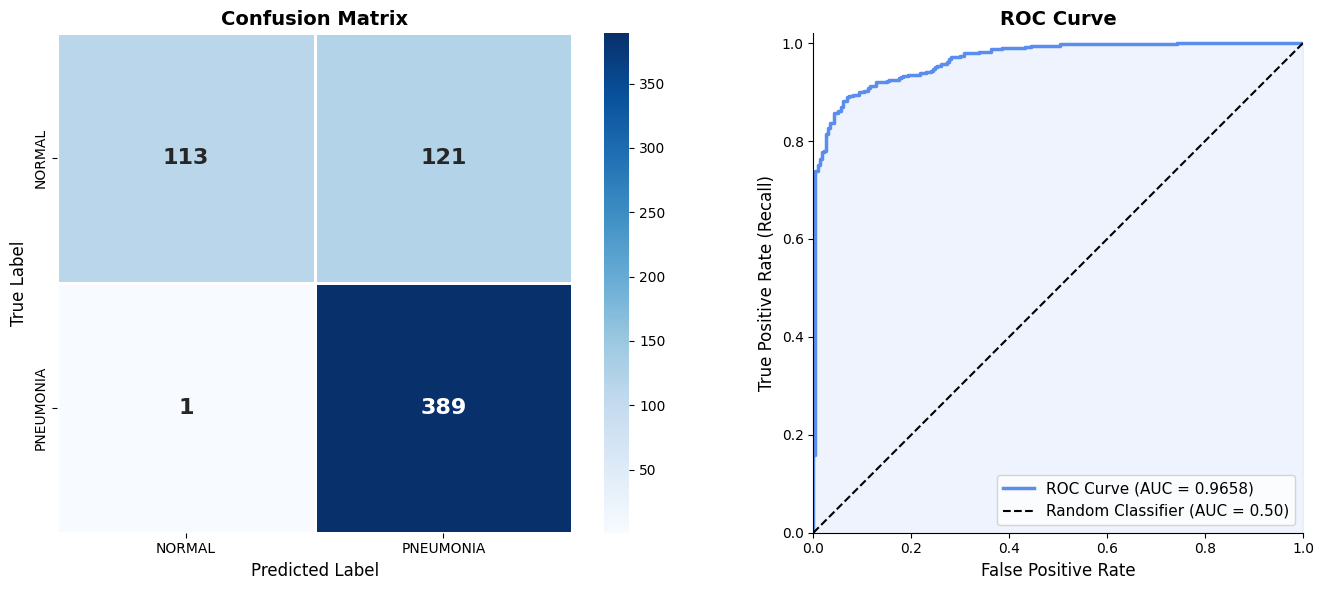


📊 Confusion Matrix Analysis:
  True Negatives  (NORMAL   → NORMAL):    113
  False Positives (NORMAL   → PNEUMONIA): 121  ← over-diagnosis
  False Negatives (PNEUMONIA → NORMAL):  1  ← missed cases (dangerous!)
  True Positives  (PNEUMONIA → PNEUMONIA): 389

  Sensitivity (Recall): 99.74%
  Specificity:          48.29%


In [15]:
# ── Step 8d: Confusion Matrix ─────────────────────────────────────────────────

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion matrix heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0],
    linewidths=1,
    linecolor='white',
    annot_kws={'size': 16, 'weight': 'bold'},
)
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# ROC Curve
axes[1].plot(fpr, tpr, color='#5b8dee', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#5b8dee')
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.02])
axes[1].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate (Recall)', fontsize=12)
axes[1].legend(loc='lower right', fontsize=11)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].set_aspect('equal')

plt.tight_layout()
plt.savefig('confusion_matrix_roc.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📊 Confusion Matrix Analysis:")
print(f"  True Negatives  (NORMAL   → NORMAL):    {tn}")
print(f"  False Positives (NORMAL   → PNEUMONIA): {fp}  ← over-diagnosis")
print(f"  False Negatives (PNEUMONIA → NORMAL):  {fn}  ← missed cases (dangerous!)")
print(f"  True Positives  (PNEUMONIA → PNEUMONIA): {tp}")
print(f"\n  Sensitivity (Recall): {tp/(tp+fn):.2%}")
print(f"  Specificity:          {tn/(tn+fp):.2%}")

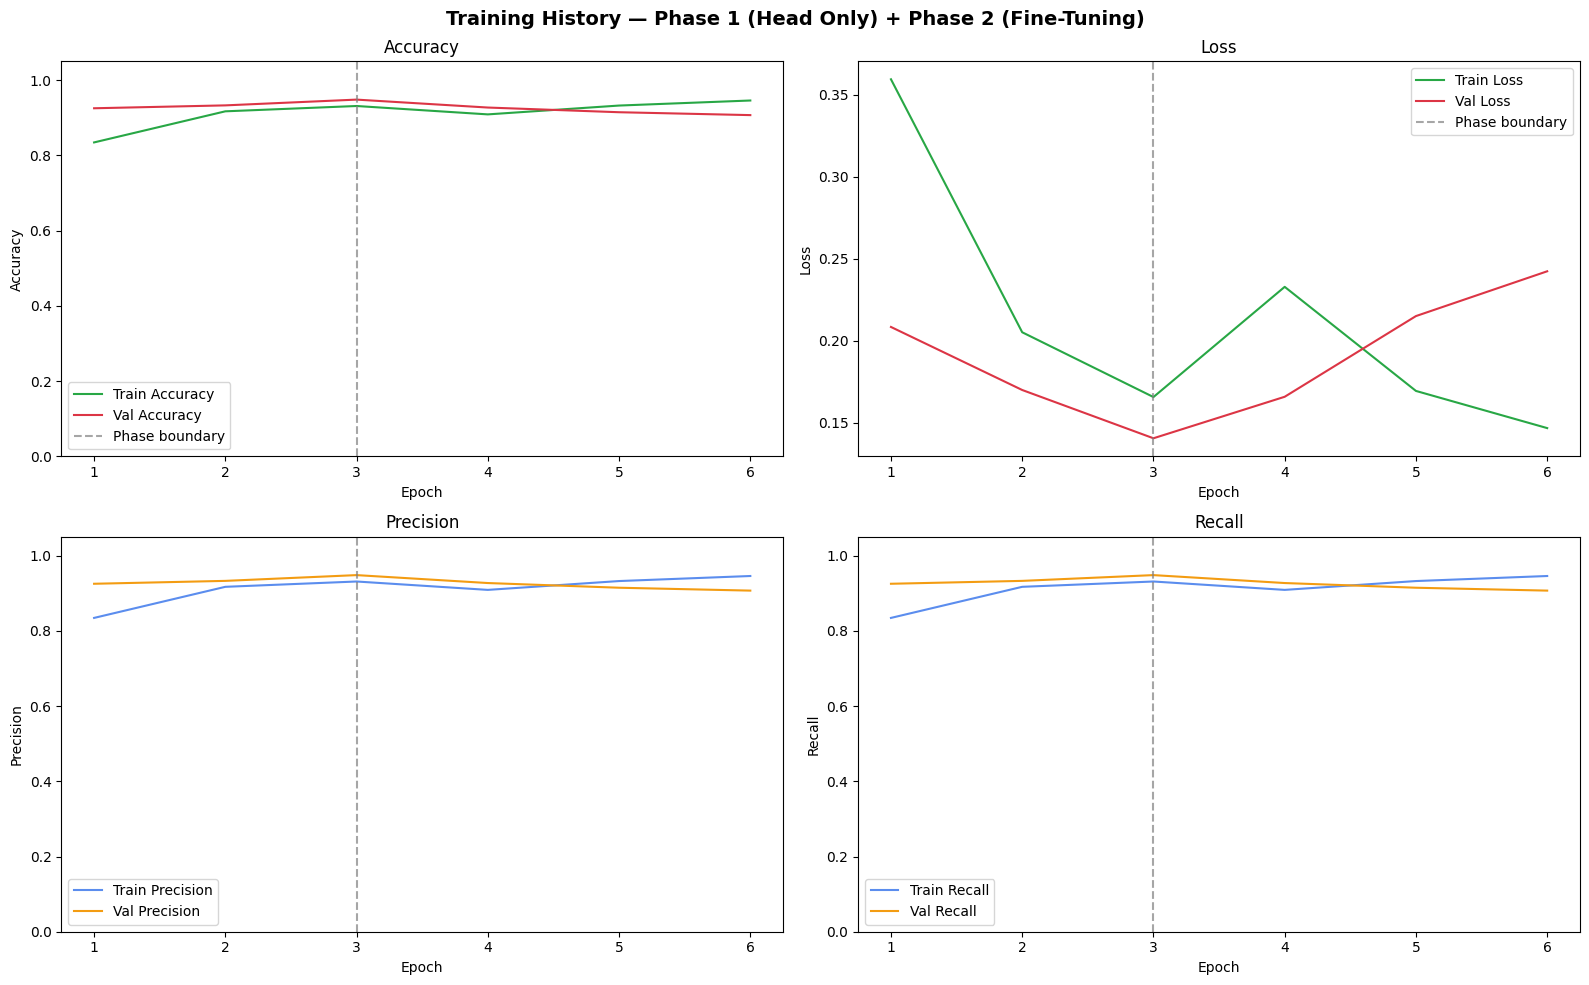


📊 Learning Curve Interpretation:
Phase 1 (before dotted line): Only the head trains — fast convergence, may plateau.
Phase 2 (after dotted line): Top base layers unfreeze — accuracy jumps further.
If train acc >> val acc, the model is overfitting → need more Dropout or augmentation.
If both curves converge and stabilise, the model has generalised well.


In [16]:
# ── Step 8e: Learning Curves ──────────────────────────────────────────────────
# Merge Phase 1 and Phase 2 histories for a complete view

def merge_histories(h1, h2):
    """Concatenate two Keras history objects."""
    merged = {}
    for key in h1.history:
        merged[key] = h1.history[key] + h2.history.get(key, [])
    return merged

full_history = merge_histories(history_phase1, history_phase2)
phase1_len   = len(history_phase1.history['accuracy'])
total_epochs = len(full_history['accuracy'])
epoch_range  = range(1, total_epochs + 1)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Training History — Phase 1 (Head Only) + Phase 2 (Fine-Tuning)', fontsize=14, fontweight='bold')

# Accuracy
axes[0,0].plot(epoch_range, full_history['accuracy'],     label='Train Accuracy', color='#28a745')
axes[0,0].plot(epoch_range, full_history['val_accuracy'], label='Val Accuracy',   color='#dc3545')
axes[0,0].axvline(phase1_len, color='gray', linestyle='--', alpha=0.7, label='Phase boundary')
axes[0,0].set_title('Accuracy')
axes[0,0].set_xlabel('Epoch')
axes[0,0].set_ylabel('Accuracy')
axes[0,0].legend()
axes[0,0].set_ylim([0, 1.05])

# Loss
axes[0,1].plot(epoch_range, full_history['loss'],     label='Train Loss', color='#28a745')
axes[0,1].plot(epoch_range, full_history['val_loss'], label='Val Loss',   color='#dc3545')
axes[0,1].axvline(phase1_len, color='gray', linestyle='--', alpha=0.7, label='Phase boundary')
axes[0,1].set_title('Loss')
axes[0,1].set_xlabel('Epoch')
axes[0,1].set_ylabel('Loss')
axes[0,1].legend()

# Precision
axes[1,0].plot(epoch_range, full_history.get('precision', [0]*total_epochs),     label='Train Precision', color='#5b8dee')
axes[1,0].plot(epoch_range, full_history.get('val_precision', [0]*total_epochs), label='Val Precision',   color='#f39c12')
axes[1,0].axvline(phase1_len, color='gray', linestyle='--', alpha=0.7)
axes[1,0].set_title('Precision')
axes[1,0].set_xlabel('Epoch')
axes[1,0].set_ylabel('Precision')
axes[1,0].legend()
axes[1,0].set_ylim([0, 1.05])

# Recall
axes[1,1].plot(epoch_range, full_history.get('recall', [0]*total_epochs),     label='Train Recall', color='#5b8dee')
axes[1,1].plot(epoch_range, full_history.get('val_recall', [0]*total_epochs), label='Val Recall',   color='#f39c12')
axes[1,1].axvline(phase1_len, color='gray', linestyle='--', alpha=0.7)
axes[1,1].set_title('Recall')
axes[1,1].set_xlabel('Epoch')
axes[1,1].set_ylabel('Recall')
axes[1,1].legend()
axes[1,1].set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Learning Curve Interpretation:")
print("Phase 1 (before dotted line): Only the head trains — fast convergence, may plateau.")
print("Phase 2 (after dotted line): Top base layers unfreeze — accuracy jumps further.")
print("If train acc >> val acc, the model is overfitting → need more Dropout or augmentation.")
print("If both curves converge and stabilise, the model has generalised well.")

---
## Step 9 — Save & Download the Model

We save the final model in `.h5` (HDF5) format — widely supported, works with the FastAPI backend.

After downloading, place the file at `models/chest_xray_model.h5` in the GitHub repo.

In [17]:
# ── Save the trained model ────────────────────────────────────────────────────

MODEL_SAVE_PATH = 'chest_xray_model.h5'
model.save(MODEL_SAVE_PATH)
print(f"Model saved to {MODEL_SAVE_PATH}")

# Check file size
size_mb = os.path.getsize(MODEL_SAVE_PATH) / (1024 * 1024)
print(f"Model file size: {size_mb:.1f} MB")

Model saved to chest_xray_model.h5
Model file size: 20.2 MB


In [18]:
# ── Download from Google Colab ────────────────────────────────────────────────
# This triggers a file download in the browser.
# Save the downloaded chest_xray_model.h5 to your project's models/ folder.

try:
    from google.colab import files
    files.download('chest_xray_model.h5')
    files.download('metrics.json')      # also download metrics for the API
    print("✅ Download triggered! Save chest_xray_model.h5 to models/ in your repo.")
except ImportError:
    print("Not running in Colab — files are saved locally.")
    print(f"Model path: {os.path.abspath('chest_xray_model.h5')}")
    print(f"Metrics path: {os.path.abspath('metrics.json')}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Download triggered! Save chest_xray_model.h5 to models/ in your repo.


---
## Step 10 — Prediction Demo

Demonstrate single-image inference — the same logic used by the FastAPI `/predict` endpoint.

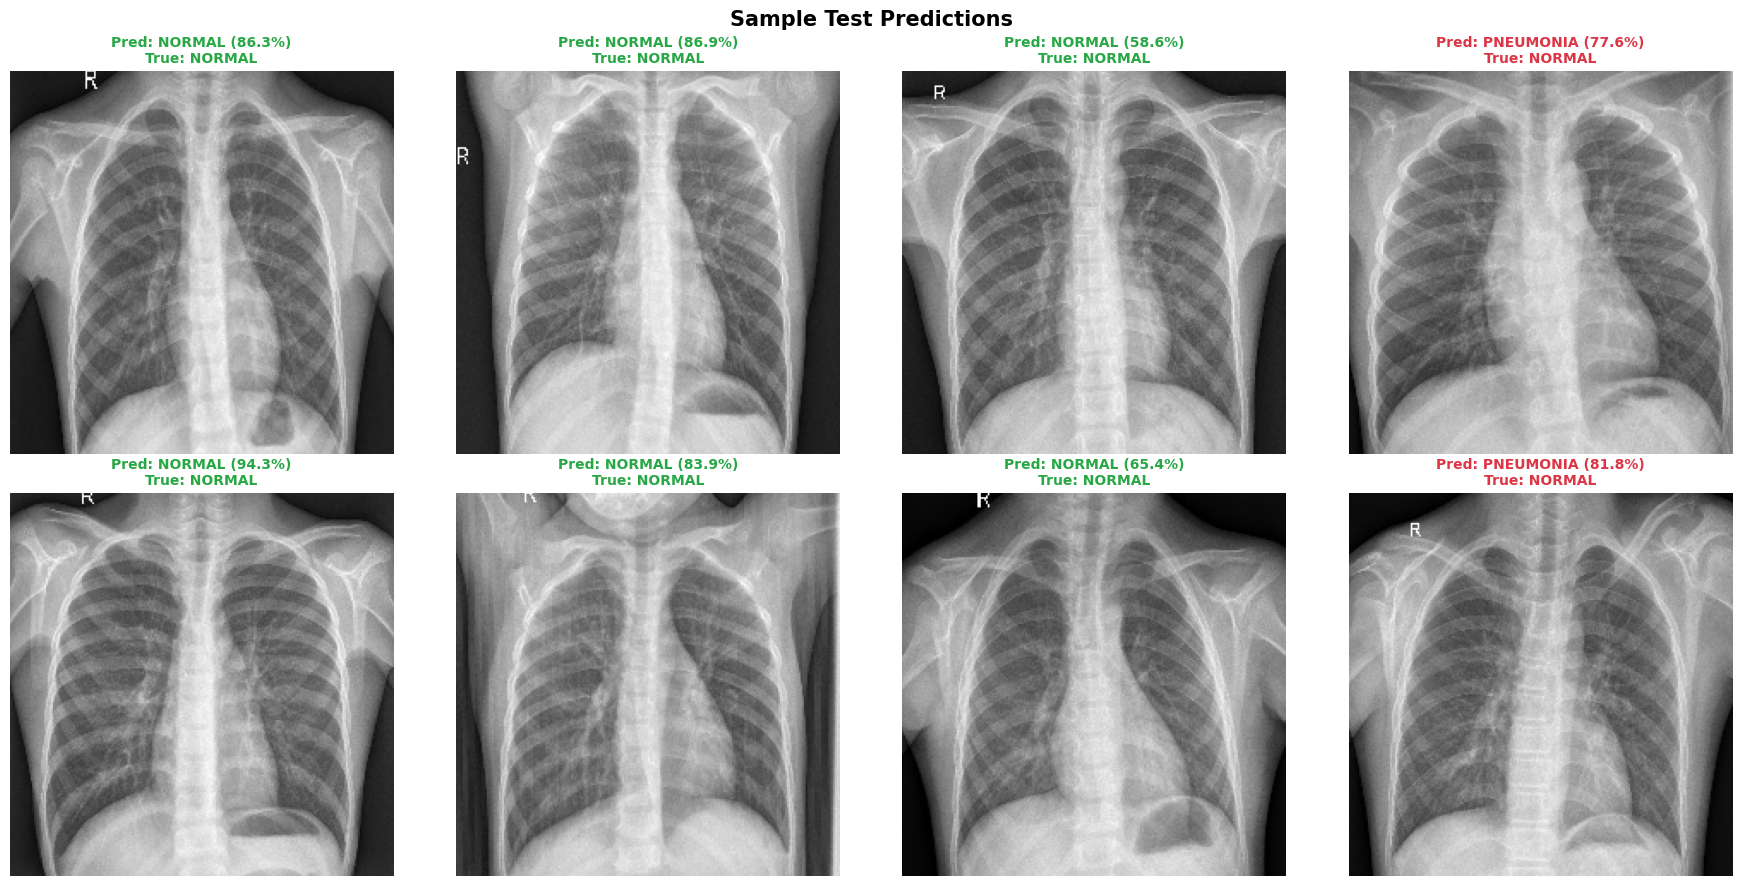


✅ Prediction demo complete!
Green title = correct prediction, Red title = incorrect prediction.


In [20]:
# ── Prediction demo: a few test images ───────────────────────────────────────

CLASS_NAMES = ['NORMAL', 'PNEUMONIA']

def predict_from_array(model, img_array, true_label=None):
    """
    Run inference on a single (1, 224, 224, 3) float32 numpy array.
    Returns a dict with class, confidence, and probabilities.
    """
    preds = model.predict(img_array, verbose=0)[0]  # shape: (2,)
    pred_idx   = int(np.argmax(preds))
    confidence = float(preds[pred_idx])
    result = {
        'class':         CLASS_NAMES[pred_idx],
        'confidence':    round(confidence, 4),
        'probabilities': {
            'NORMAL':    round(float(preds[0]), 4),
            'PNEUMONIA': round(float(preds[1]), 4),
        },
    }
    if true_label is not None:
        result['true_label'] = CLASS_NAMES[true_label]
        result['correct']    = (pred_idx == true_label)
    return result


# Show 8 test predictions
n_demo = 8
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Sample Test Predictions', fontsize=15, fontweight='bold')

test_gen.reset()
sample_count = 0

for images, labels in test_gen:
    for i in range(len(images)):
        if sample_count >= n_demo:
            break
        img_np   = images[i]                     # (224, 224, 3)
        true_lbl = int(np.argmax(labels[i]))
        img_batch = np.expand_dims(img_np, axis=0)  # (1, 224, 224, 3)

        result = predict_from_array(model, img_batch, true_label=true_lbl)

        row, col = divmod(sample_count, 4)
        ax = axes[row][col]
        ax.imshow(img_np)
        color = '#28a745' if result['correct'] else '#dc3545'
        ax.set_title(
            f"Pred: {result['class']} ({result['confidence']:.1%})\nTrue: {result['true_label']}",
            color=color, fontsize=10, fontweight='bold'
        )
        ax.axis('off')
        sample_count += 1

    if sample_count >= n_demo:
        break

plt.tight_layout()
plt.savefig('prediction_demo.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Prediction demo complete!")
print("Green title = correct prediction, Red title = incorrect prediction.")